# Detect differential item functioning with TIRT

**Experimental.** The DIF API and defaults may change.

A group can differ in average ability, in how a comparison works at the same
ability, or both. In this example some comparison cutpoints differ between
groups (uniform DIF) and some statement loadings differ (nonuniform DIF).
Lee et al. (2021) investigated both
types of DIF with a TIRT model for three-statement blocks. Here we use
two-statement blocks to illustrate the two effects.

## Model

For a given respondent and comparison pair, the probability of choosing
the first statement in group $g$ is

$$
\Pr(Y=1\mid\boldsymbol\theta,g)
=
\Phi\!\left(\gamma_g+k_1a_{1g}\theta_1-k_2a_{2g}\theta_2\right).
$$

Here $\Phi$ is the standard normal CDF. For statement $s$, $\theta_s$ is the
respondent's score on its trait, $k_s$ is its keying, and $a_{sg}>0$ is its
loading magnitude. The comparison intercept $\gamma_g$ combines the cutpoint
and the difference between the statement intercepts.

Relative to group A, the group B intercept and statement loadings are

$$
\begin{aligned}
\gamma_B &= \gamma_A + \Delta_\gamma,\\
\log a_{sB} &= \log a_{sA} + \Delta_{a,s},\qquad s=1,2.
\end{aligned}
$$

**Intercept DIF** is the difference $\Delta_\gamma$. The B-minus-A
cutpoint difference reported by the API equals $-\Delta_\gamma$.
**Loading DIF** is the shift $\Delta_{a,s}$ on the log scale.
For B03_1, the generating loadings are 0.90 in A and 0.45 in B, so
$\Delta_{a,1}=\log(0.5)$. The API reports the difference on the original
loading scale, which is $0.45-0.90=-0.45$ in this example.

In [1]:
import arviz_stats as azs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import pyfcirt as fc

## Generate one dataset

Simulate 800 people, split equally between groups A and B, answering 12 pairs.
Each trait pairing appears four times: Trait 1 with Trait 2, Trait 2 with
Trait 3, and Trait 1 with Trait 3. Group B has trait mean
shifts of 0.45, -0.30 and 0.20. Its cutpoints shift by +1.50, -1.50 and +1.50 in
B02, B06 and B10, respectively.

In group B, statement B03_1 changes loading magnitude from 0.90 to 0.45,
and B07_1 changes from 0.90 to 1.80. All other generating loadings are
shared. Generating statement effects are zero. The model allows each
of the 24 loadings and 12 cutpoints to vary across groups.

In [2]:
rng = np.random.default_rng(730026)
n = 800
# Repeat each cross-trait pairing four times.
blocks = [f"B{i:02d}" for i in range(1, 13)]
traits = np.tile([(0, 1), (1, 2), (0, 2)], (4, 1))
# Assign equal group sizes and randomize the respondent order.
group = rng.permutation(np.repeat([0, 1], n // 2))
people = pd.DataFrame({"person_id": np.arange(n), "site": np.where(group, "B", "A")})
people["site"] = pd.Categorical(people["site"], categories=["A", "B"])
# Give group B different trait means within the same covariance structure.
correlation = [[1, 0.35, -0.15], [0.35, 1, 0.25], [-0.15, 0.25, 1]]
theta = rng.multivariate_normal([0, 0, 0], correlation, size=n)
theta += group[:, None] * np.array([0.45, -0.30, 0.20])

loadings = np.tile([0.9, 1.1], (len(blocks), 1))
# Use opposite keying in half the pairs and positive keying in the rest.
keying = np.tile([1, -1], (len(blocks), 1))
keying[[1, 3, 5, 7, 9, 11], 1] = 1
design = pd.DataFrame(
    [
        (block, j + 1, f"{block}_{j + 1}", f"Trait {traits[k, j] + 1}", keying[k, j])
        for k, block in enumerate(blocks)
        for j in (0, 1)
    ],
    columns=["block_id", "position", "statement_id", "trait", "keying"],
)
# Plant three cutpoint differences and two loading differences in group B.
cutpoint_shift = np.zeros(len(blocks))
cutpoint_shift[[1, 5, 9]] = [1.5, -1.5, 1.5]
loading_shift = np.zeros_like(loadings)
loading_shift[[2, 6], 0] = [-0.45, 0.90]
# Subtract the second statement's utility from the first in each pair.
person_loadings = loadings + group[:, None, None] * loading_shift
utility = (theta[:, traits] * person_loadings * keying) @ np.array([1, -1])
threshold = np.linspace(-0.5, 0.5, len(blocks)) + group[:, None] * cutpoint_shift
# Record 1 when the noisy utility difference exceeds the group-specific cutpoint.
choices = (utility + rng.normal(size=threshold.shape) >= threshold).astype(int)
responses = pd.DataFrame(
    {
        "person_id": np.repeat(people.person_id.to_numpy(), len(blocks)),
        "block_id": np.tile(blocks, n),
        "response": choices.ravel(),
    }
)

In [3]:
responses.head()

,person_id,block_id,response
0,0,B01,0
1,0,B02,0
2,0,B03,1
3,0,B04,1
4,0,B05,0


## Define the model

Register the design and responses, then set A as the reference group. Group B's
trait means and covariance are estimated. Multiplying a focal trait by a
positive constant and dividing its loadings by that constant gives the same
response probabilities. Without anchors, the model relies on the assumption
that most loadings are similar across groups. Prepare the data once for all
three fits.

In [4]:
model = fc.Model()
model.add_fc(
    design,
    responses,
    format="block_long",
    model=fc.TIRT(residuals="fixed"),
    response_format=None,
)
model.set_population(group="site", reference_group="A", person_data=people)
prepared = model.prepare().prepared

## Fit three DIF priors

Laplace shrinks coefficients relative to the reference level (Park & Casella,
2008). Pairwise L1 shrinks differences between all group pairs. The truncated
version caps that penalty and adds a normal base distribution (Lyu et al.,
2025). All three fits use the same priors for the reference-group loadings
and cutpoints. Each DIF prior uses its default shrinkage settings.

In [5]:
targets = ["fc.loading_magnitude", "fc.cutpoints"]
fits = {}
for prior in ("laplace", "pairwise_l1", "truncated_l1"):
    model = fc.Model(prepared)
    model.add_dif_terms(targets, person_data=people, formula="site", prior=prior)
    model.fit(chains=4, tune=2000, draws=2000, random_seed=33)
    fits[prior] = model

## Check sampling

Check the maximum R-hat across posterior variables and the number of
divergences in each fit. Fixed entries have undefined R-hat.

In [6]:
for prior, model in fits.items():
    rhat = azs.rhat(model.idata.posterior.dataset)
    max_rhat = float(rhat.max(skipna=True).to_array().max(skipna=True))
    divergences = int(model.idata.sample_stats.diverging.sum())
    print(f"{prior}: max R-hat = {max_rhat:.3f}, divergences = {divergences}")

laplace: max R-hat = 1.025, divergences = 0


pairwise_l1: max R-hat = 1.043, divergences = 0


truncated_l1: max R-hat = 1.042, divergences = 0


## Compare DIF contrasts

The estimates compare B with A on the original parameter scale. A positive
cutpoint difference means B requires a larger utility advantage to choose
the first statement. A positive loading difference means a larger loading
magnitude in B. The points show posterior means, the bars show 95% equal-tailed
intervals, and the diamonds show the generating differences.

In [7]:
contrasts = pd.concat(
    [model.dif_summary({"site": ("A", "B")}).assign(prior=prior) for prior, model in fits.items()],
    ignore_index=True,
)

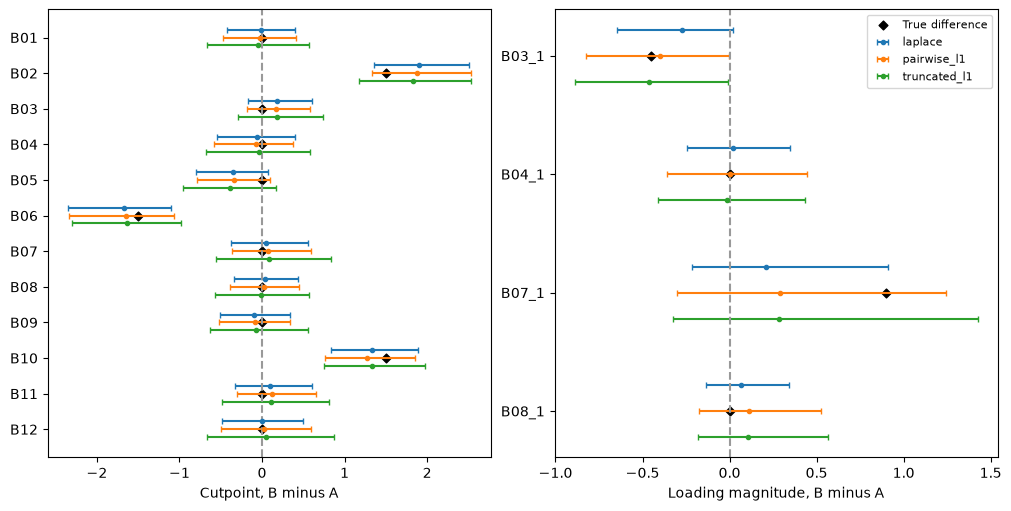

In [8]:
cutpoints = contrasts.loc[contrasts.parameter == "cutpoint"].assign(
    label=lambda rows: rows.units.str[0]
)
loadings = contrasts.loc[contrasts.parameter == "loading"].rename(columns={"statement": "label"})
selected = ["B03_1", "B04_1", "B07_1", "B08_1"]
truth = pd.Series(loading_shift.ravel(), index=design.statement_id)

fig, axes = plt.subplots(1, 2, figsize=(10, 5), layout="constrained")
for ax, rows, known, label in [
    (axes[0], cutpoints, pd.Series(cutpoint_shift, index=blocks), "Cutpoint"),
    (axes[1], loadings, truth.loc[selected], "Loading magnitude"),
]:
    positions = np.arange(len(known))
    for offset, (prior, values) in zip(
        (-0.22, 0, 0.22), rows.groupby("prior", sort=False), strict=True
    ):
        values = values.set_index("label").loc[known.index]
        ax.errorbar(
            values["mean"],
            positions + offset,
            xerr=[values["mean"] - values.lower, values.upper - values["mean"]],
            fmt="o",
            ms=3,
            capsize=2,
            label=prior,
        )
    ax.scatter(known, positions, marker="D", color="black", s=20, label="True difference")
    ax.axvline(0, color="0.6", ls="--")
    ax.set(yticks=positions, yticklabels=known.index, xlabel=f"{label}, B minus A")
    ax.invert_yaxis()
axes[1].legend(loc="best", fontsize=8)
plt.show()

All three fits flag the cutpoint differences in B02, B06 and B10. Both
pairwise priors flag the loading difference for B03_1. For B07_1, all
three intervals include zero.

## Anchor a block

To treat B01 as invariant, anchor both statement loadings and the cutpoint
for their comparison. The model estimates these three common values from
the data. The earlier fits leave all DIF terms free.

In [9]:
anchored = fc.Model(prepared)
anchored.add_dif_terms(
    {
        "fc.loading_magnitude": {"anchors": ["B01_1", "B01_2"]},
        "fc.cutpoints": {"anchors": [("B01", "B01_1", "B01_2")]},
    },
    person_data=people,
    formula="site",
)

## Report Bayes factors

A Bayes factor compares a free group effect with a zero group effect. For B03_1 and B04_1, the Bayes factors use the log-loading difference. The mean difference stays on the original loading scale.

In [9]:
evidence = fits["laplace"].dif_summary(
    {"site": ("A", "B")}, bayes_factor=True, random_seed=20261127
)
evidence.loc[
    evidence.statement.isin(["B03_1", "B04_1"]), ["statement", "mean", "BF10", "BF01"]
].round(2)

,statement,mean,BF10,BF01
4,B03_1,-0.28,4.51,0.22
6,B04_1,0.02,0.85,1.18


## References

Lee, P., Joo, S.-H., & Stark, S. (2021). Detecting DIF in multidimensional forced choice measures using the Thurstonian item response theory model. *Organizational Research Methods, 24*(4), 739–771. [https://doi.org/10.1177/1094428120959822](https://doi.org/10.1177/1094428120959822)

Lyu, W., Wang, C., & Xu, G. (2025). Detecting differential item functioning across multiple groups using group pairwise penalty. *Psychometrika, 90*(5), 1594–1621. [https://doi.org/10.1017/psy.2025.10034](https://doi.org/10.1017/psy.2025.10034)

Park, T., & Casella, G. (2008). The Bayesian lasso. *Journal of the American Statistical Association, 103*(482), 681–686. [https://doi.org/10.1198/016214508000000337](https://doi.org/10.1198/016214508000000337)